# SiN Straight Waveguide -- Meep Baseline and Comparison with Si

First notebook of the **SiN track**. It repeats the Si track's
`si/notebooks/01_waveguide_baseline.ipynb` for a 400 nm silicon-nitride strip and then
compares the two platforms' guided modes. The comparison sets up the next notebook:
a weakly confined mode needs a much larger bend radius.

1. **Component definition** -- the SiN parameter set, and how a 900 × 400 nm strip
   becomes a 2D core index (effective-index method, calibrated on a cross-section mode
   solve).
2. **GDSFactory geometry** and 3. **geometry visualization**.
4. **2D Meep FDTD simulation** -- baseline run, field, S-parameters, length sweep.
5. **SAX model fitting** -- cutback $n_\mathrm{eff}$ and MPB $n_g$.
6. **Sanity checks**, 7. **save artifact and design point**.
8. **SiN vs. Si** -- mode profiles, index contrast, confinement, against a Si strip
   calibrated the same way.

Kernel: `mp` conda env, run from `sin/notebooks/`. Platform choices and sources are in
`sin/literature.md`.

**Do not use "Run All."** Work through the notebook step by step, and stop at the
marked checkpoints to actually look at the plots before continuing.

## 1. Component definition -- SiN parameter set

The SiN track starts from `pic_toolkit.params.SIN_GLOBAL_PARAMS`, which is the Si
track's `GLOBAL_PARAMS` with three overrides:

| Parameter | Si track | SiN track | Basis |
|---|---|---|---|
| film | (simplified) | 400 nm LPCVD SiN, n = 2.0, SiO₂ clad | standard MPW stack (Applied Nanotools, IME), `sin/literature.md` |
| `core_index` | 2.7 | 1.7650 | n_eff-matched 2D index of the 900 × 400 nm strip at 1.35 µm (Section 1.1) |
| `wg_width_um` | 0.5 | 0.9 | Toronto-IME 400 nm SiN strip width |

The wavelength band (1.30--1.40 µm), cladding (1.44), TE polarization and PML are the
same as in the Si track, so every difference below comes from the waveguide itself.
Materials are non-dispersive, as in the rest of the toolkit.

In [1]:
import inspect
import json

import numpy as np
import matplotlib.pyplot as plt
import gdsfactory as gf
import yaml

from pic_toolkit.params import SIN_GLOBAL_PARAMS
from pic_toolkit.meep_sim import waveguide
from pic_toolkit import checks, viz, sparams, design_points, sweep, style, slab_modes

style.apply_style()
%matplotlib inline

In [2]:
# waveguide.py's DEFAULT_PARAMS (length, margins) + the SiN parameter set. The only
# component-level override is cell_y_um: the SiN mode's evanescent tail is about
# twice as long as the Si mode's, and with the Si track's 4 um cell the mode monitors
# (cell_y_um - 2*dpml_um wide) clip it -- |S21|^2 read 0.9997 at 4 um and 1.0000 at
# 6 um (docs/simulation_settings_record.md, SiN track section).
params = waveguide.derive_lengths({**waveguide.DEFAULT_PARAMS, **SIN_GLOBAL_PARAMS, "cell_y_um": 6.0})

print("SiN parameter set (pic_toolkit.params.SIN_GLOBAL_PARAMS)")
print(f"  SiN film thickness   : {params['sin_thickness_um']} um (n = 2.0)")
print(f"  waveguide width      : {params['wg_width_um']} um")
print(f"  core / clad index    : {params['core_index']} / {params['clad_index']}  (2D effective index)")
print(f"  polarization         : {params['polarization']}")
print(f"  wavelength band      : {params['wl_min_um']}-{params['wl_max_um']} um")
print(f"  resolution           : {params['resolution']} px/um")
print()
print("Component-specific parameters")
print(f"  characterized length : {params['length_um']} um")
print(f"  cell_y_um            : {params['cell_y_um']} um  (Si track: 4.0)")

SiN parameter set (pic_toolkit.params.SIN_GLOBAL_PARAMS)
  SiN film thickness   : 0.4 um (n = 2.0)
  waveguide width      : 0.9 um
  core / clad index    : 1.765 / 1.44  (2D effective index)
  polarization         : TE
  wavelength band      : 1.3-1.4 um
  resolution           : 20 px/um

Component-specific parameters
  characterized length : 4.0 um
  cell_y_um            : 6.0 um  (Si track: 4.0)


### 1.1 From a 900 × 400 nm strip to a 2D core index

This toolkit simulates a 2D plane, so the vertical layer stack has to be collapsed into a
single core index. Two steps:

1. **Slab effective-index method.** The film's TE₀ slab mode (E parallel to the layers)
   has an effective index $n_\mathrm{slab}$. `slab_modes.te_slab_index` solves the
   symmetric-slab condition
   $$\tan u = \frac{\sqrt{V^2-u^2}}{u},\qquad u=\tfrac{k_0 t}{2}\sqrt{n_f^2-n_\mathrm{slab}^2},\quad V=\tfrac{k_0 t}{2}\sqrt{n_f^2-n_c^2}.$$
   A strip with core $n_\mathrm{slab}$ is then solved laterally. This is the textbook
   method. It is known to **overestimate** the mode index of a strip, because it ignores
   the field that leaks out of the corners of the cross-section.
2. **Calibration (n_eff matching).** The real cross-section is solved as a 2D eigenproblem
   with MPB, and the 2D core index is chosen so that the lateral TE₀ mode of the 2D model
   has exactly that $n_\mathrm{eff}$ (`slab_modes.core_index_for_neff`). This is the idea
   behind Lumerical's varFDTD.

For bends the calibration matters. Radiation depends on how far the mode index sits above
the cladding, $n_\mathrm{eff}-n_\mathrm{clad}$, and through the WKB exponent it depends on
that difference roughly to the power 3/2 (notebook 02 §9.5). For SiN this difference is
only ≈ 0.24, so an error of 0.01 in $n_\mathrm{eff}$ already shifts it by 5 %.

The same two steps are applied to a 500 × 220 nm Si strip. That **Si reference** is what
notebook 02 compares the SiN bend against.

In [3]:
# Slab index (step 1), MPB cross-section n_eff (reference), and the calibrated 2D core
# index (step 2) for the SiN strip and the Si reference strip, at the band center.
import meep as mp
from meep import mpb
from pic_toolkit.params import SI_REF_PARAMS, GLOBAL_PARAMS

mp.verbosity.mpb = 0  # MPB's per-iteration log adds nothing here

def cross_section_neff(width, thickness, n_film, n_clad, wl, resolution):
    # Fundamental (TE-like for width > thickness) mode of the rectangular core in a
    # uniform cladding, 1.5 um of cladding on every side.
    ms = mpb.ModeSolver(
        geometry_lattice=mp.Lattice(size=mp.Vector3(width + 3.0, thickness + 3.0, 0)),
        geometry=[mp.Block(size=mp.Vector3(width, thickness, mp.inf), material=mp.Medium(index=n_film))],
        default_material=mp.Medium(index=n_clad), resolution=resolution, num_bands=1)
    ms.verbose = False
    f = 1 / wl
    k = ms.find_k(mp.NO_PARITY, f, 1, 1, mp.Vector3(0, 0, 1), 1e-6, 0.8 * n_film * f, n_clad * f, n_film * f)
    return k[0] / f

wl_c = 1.35
strips = {
    # name: (width, thickness, film index, MPB resolution, params set). The thin Si film
    # needs a finer grid: its n_eff converges to +-0.001 only from ~80 px/um.
    "SiN 900 x 400 nm": (params["wg_width_um"], params["sin_thickness_um"], 2.00, 64, params),
    "Si 500 x 220 nm": (SI_REF_PARAMS["wg_width_um"], SI_REF_PARAMS["si_thickness_um"], 3.50, 128, SI_REF_PARAMS),
}
calibration = {}
print(f"{'':18s} {'slab index':>10s} {'slab-EIM n_eff':>15s} {'MPB n_eff':>10s} {'calibrated core':>16s} {'params':>8s}")
for name, (w, t, n_film, res, pset) in strips.items():
    n_slab = slab_modes.te_slab_index(t, n_film, params["clad_index"], wl_c)
    n_eim = slab_modes.n_eff_single(wl_c, width=w, n_core=n_slab, n_clad=params["clad_index"], span=8.0)
    n_mpb = cross_section_neff(w, t, n_film, params["clad_index"], wl_c, res)
    n_core = slab_modes.core_index_for_neff(n_mpb, w, params["clad_index"], wl_c)
    calibration[name] = dict(n_slab=n_slab, n_eim=n_eim, n_mpb=n_mpb, n_core=n_core)
    print(f"{name:18s} {n_slab:10.4f} {n_eim:15.4f} {n_mpb:10.4f} {n_core:16.4f} {pset['core_index']:8.4f}")
    assert abs(n_core - pset["core_index"]) < 2e-3, f"{name}: params core_index is not the calibrated value"

n_si_track = slab_modes.n_eff_single(wl_c, width=GLOBAL_PARAMS["wg_width_um"], n_core=GLOBAL_PARAMS["core_index"],
                                     n_clad=GLOBAL_PARAMS["clad_index"], span=8.0)
print(f"\nSi track (core {GLOBAL_PARAMS['core_index']}, 0.5 um): 2D n_eff {n_si_track:.4f} "
      f"vs. real 500 x 220 nm strip {calibration['Si 500 x 220 nm']['n_mpb']:.4f}")

                   slab index  slab-EIM n_eff  MPB n_eff  calibrated core   params


SiN 900 x 400 nm       1.7786          1.6878     1.6754           1.7650   1.7650


Si 500 x 220 nm        2.9676          2.6959     2.6713           2.9441   2.9440



Si track (core 2.7, 0.5 um): 2D n_eff 2.4184 vs. real 500 x 220 nm strip 2.6713


**Reading the calibration:**

- **SiN.** The slab method gives a 2D n_eff of 1.6878, against 1.6753 for the real
  cross-section.
  - The excess over the cladding is therefore 0.248 instead of 0.235, i.e. 5 % too large.
  - The calibrated core index 1.7650 removes that, and is what `SIN_GLOBAL_PARAMS` uses.
- **Si reference.** The slab method overestimates by 0.025 (2.696 against 2.671). The
  calibrated core is 2.944.
- **Si track.** Its simplified core of 2.7 gives a mode index of 2.418, **0.25 below** a
  real 500 × 220 nm strip. A Si track bend is therefore much less confined than a real Si
  bend, and is not a fair partner for the SiN comparison. Notebook 02 §9.1 checks this
  against published 3D FDTD.
- **Convergence of the MPB values.**
  - SiN: n_eff at 32 / 48 / 64 px/µm agrees to 2×10⁻⁴.
  - Si: the 220 nm film is only a few cells thick on a coarse grid, so n_eff converges to
    about ±0.001 only from 80 px/µm upwards (80 / 100 / 128 px/µm: 2.6697 / 2.6701 /
    2.6713). Hence 128 px/µm above.
- **What the model leaves out.** The 2D model is non-dispersive, and the calibration
  holds at the band center. Radiation into the cladding above and below the film exists
  only in 3D, and so does the exact shape of the field near the strip's corners. Whether
  these matter for bend loss is tested directly in notebook 02 §9.1, by comparing the
  calibrated 2D model with published 3D FDTD and measurements.

### 1.2 Width: lateral modes of the 2D strip

With the 2D core index fixed, the lateral (in-plane) modes of the strip set the width.
The plot shows TE₀ and TE₁ effective indices against width from the 1D mode solver
(`slab_modes.slab_modes`, meep-free). A mode is guided while its index stays above the
cladding's 1.44.

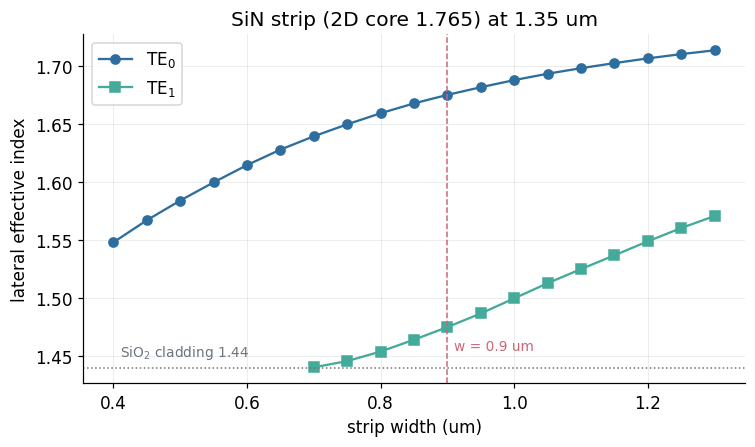

TE1 cutoff width at 1.30 um: 0.637 um
TE1 cutoff width at 1.35 um: 0.661 um
TE1 cutoff width at 1.40 um: 0.686 um
at w = 0.9 um: TE0 1.6753, TE1 1.4750


In [4]:
# Lateral TE0/TE1 of the SiN strip vs. width at the band center. A mode with n_eff
# below the cladding index is a box mode of the finite solver window, not a guided
# mode, so it is masked. The analytic TE1 cutoff of a symmetric slab is
# V = pi, i.e. w_c = wl / (2 sqrt(n_core^2 - n_clad^2)).
widths = np.round(np.arange(0.4, 1.31, 0.05), 3)
n_modes_w = np.array([
    slab_modes.slab_modes(None, width=w, n_core=params["core_index"], n_clad=params["clad_index"],
                          wl=1.35, dy=0.004, span=8.0, n_modes=2)[0]
    for w in widths
])
guided = n_modes_w > params["clad_index"]

def te1_cutoff(wl):
    return wl / (2 * np.sqrt(params["core_index"] ** 2 - params["clad_index"] ** 2))

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(widths, np.where(guided[:, 0], n_modes_w[:, 0], np.nan), "o-", color=style.COLOR_STEEL, label="TE$_0$")
ax.plot(widths, np.where(guided[:, 1], n_modes_w[:, 1], np.nan), "s-", color=style.COLOR_TEAL, label="TE$_1$")
ax.axhline(params["clad_index"], color=style.COLOR_REFERENCE, ls=":", lw=1)
ax.axvline(params["wg_width_um"], color=style.COLOR_ROSE, ls="--", lw=1)
ax.text(params["wg_width_um"] + 0.01, 1.455, f"w = {params['wg_width_um']} um", color=style.COLOR_ROSE, fontsize=9)
ax.text(0.41, 1.445, "SiO$_2$ cladding 1.44", color=style.COLOR_REFERENCE, fontsize=9, va="bottom")
ax.set_xlabel("strip width (um)")
ax.set_ylabel("lateral effective index")
ax.set_title(f"SiN strip (2D core {params['core_index']}) at 1.35 um")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

for wl in (params["wl_min_um"], 1.35, params["wl_max_um"]):
    print(f"TE1 cutoff width at {wl:.2f} um: {te1_cutoff(wl):.3f} um")
i_w = int(np.argmin(np.abs(widths - params["wg_width_um"])))
print(f"at w = {params['wg_width_um']} um: TE0 {n_modes_w[i_w, 0]:.4f}, TE1 {n_modes_w[i_w, 1]:.4f}")

In this 2D model the strip is strictly single-mode only below about 0.64 µm across the band
(0.637 / 0.661 / 0.686 µm at 1.30 / 1.35 / 1.40 µm).
The chosen 0.9 µm, the width used on the real 400 nm platform, therefore also carries a
weakly guided TE₁ (index close to the cladding's). Every source and monitor here launches
and measures TE₀ only (`eig_band=1`, `eig_parity=mp.TE`), and a straight waveguide cannot
convert TE₀ to TE₁. In a bend the weakly guided TE₁ radiates first, so a TE₀→TE₁
conversion counts as loss there, which is what a real circuit would see.

## 2. GDSFactory geometry

The same builder as in the Si track: `build_gf_component` makes exactly `length_um` of
`gf.components.straight` on a `gf.cross_section.strip` of the SiN width.

In [5]:
# Build the DUT as a gdsfactory Component and print its bounding box and ports as a
# numeric sanity check before rendering or simulating anything.
gf_component = waveguide.build_gf_component(params)
print(f"gdsfactory Component, bbox (um) = {gf_component.dbbox()}")
for p in gf_component.ports:
    print(f"  port {p.name}: center={tuple(p.dcenter)} um, width={p.dwidth} um")

gdsfactory Component, bbox (um) = (-2,-0.45;2,0.45)
  port o1: center=(-2.0, 0.0) um, width=0.9 um
  port o2: center=(2.0, 0.0) um, width=0.9 um


## 3. Geometry visualization

The gdsfactory layout and the Meep permittivity map derived from it, next to the native
`mp.Block` reference geometry.

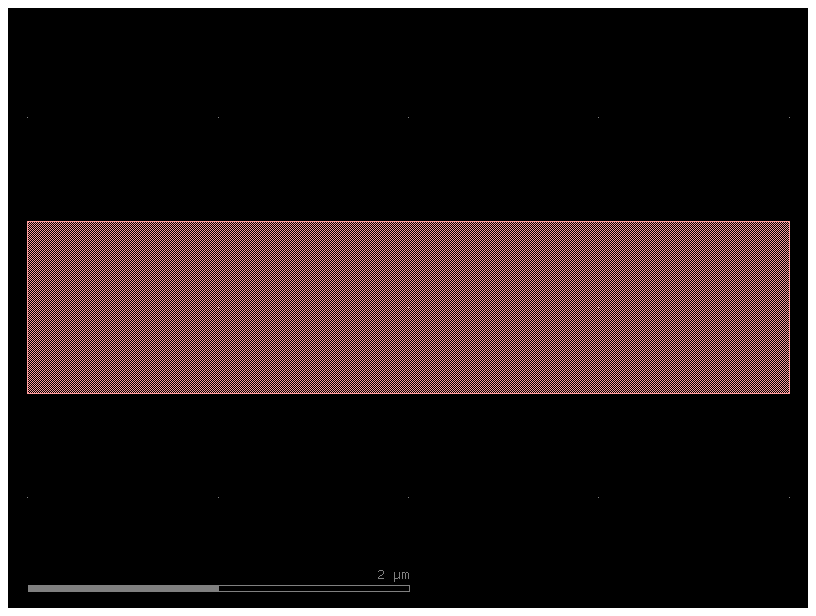

In [6]:
fig = gf_component.plot()
plt.show()

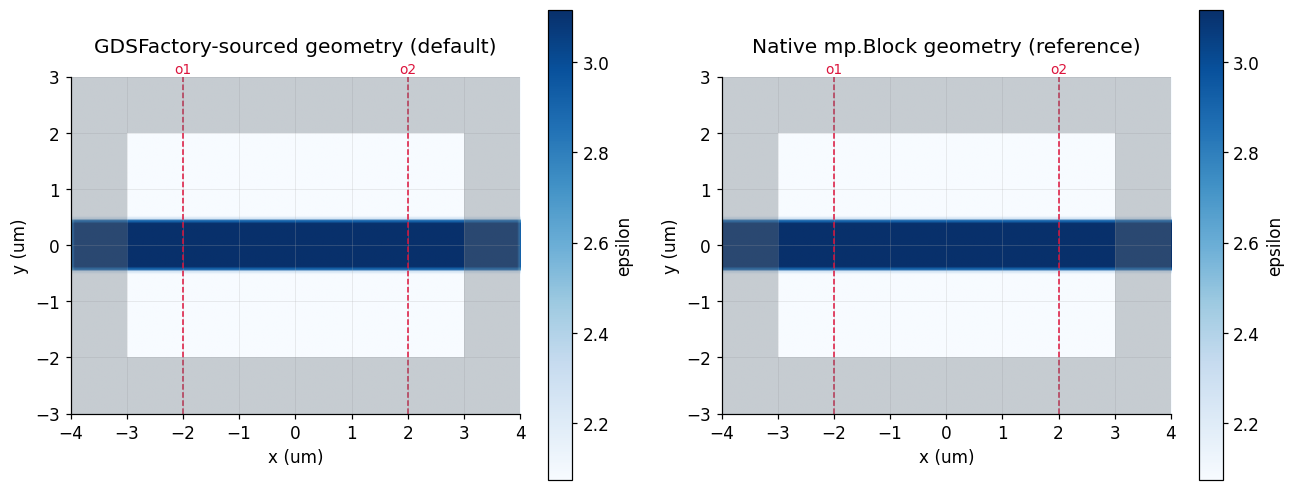

max |native - gds| eps inside the characterized span: 4.441e-16


In [7]:
# GDS-derived vs. native permittivity maps (no FDTD timestepping). Inside the
# characterized span the two must agree to floating-point noise; outside it they
# differ by design (finite access stubs vs. an infinite block).
perm_map_gds = waveguide.get_permittivity_map(params, use_native_geometry=False)
perm_map_native = waveguide.get_permittivity_map(params, use_native_geometry=True)

ports = [(-params["port_offset_um"], 0, "o1", "v"), (params["port_offset_um"], 0, "o2", "v")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
viz.plot_permittivity(perm_map_gds.eps, perm_map_gds.extent_um, ax=axes[0], ports=ports, pml_um=params["dpml_um"])
axes[0].set_title("GDSFactory-sourced geometry (default)", pad=16)
viz.plot_permittivity(perm_map_native.eps, perm_map_native.extent_um, ax=axes[1], ports=ports, pml_um=params["dpml_um"])
axes[1].set_title("Native mp.Block geometry (reference)", pad=16)
fig.tight_layout()
plt.show()

nx, _ = perm_map_native.eps.shape
xs = np.linspace(*perm_map_native.extent_um[:2], nx)
inside = np.abs(xs) < params["port_offset_um"] - 0.05
print(f"max |native - gds| eps inside the characterized span: "
      f"{np.abs(perm_map_native.eps[inside] - perm_map_gds.eps[inside]).max():.3e}")

The permittivity contrast is much smaller than in the Si track: ε = 3.16 in the core
against 2.07 in the cladding, where the Si track has 7.29 against 2.07. Each map is
colour-scaled to its own range, so the core looks equally dark in both tracks' figures.

> **STOP -- inspect both permittivity maps before running any FDTD.**
>
> Check: is the 0.9 µm core centered and surrounded by cladding? Do the panels agree
> between the port lines? Is there visible PML clearance beyond the ports, and room on
> both sides of the core for the longer SiN mode tail?

## 4. 2D Meep FDTD simulation

### 4.1-4.2 Baseline run (single length)

Two independent runs (excite `o1`, then `o2`) measure the full 2×2 S-matrix, exactly as
in the Si track.

In [8]:
# Full two-port characterization of the 4 um SiN straight.
result = waveguide.simulate_baseline(params)
print(f"{len(result.wavelengths_um)} wavelength points, "
      f"{result.wavelengths_um.min():.4f}-{result.wavelengths_um.max():.4f} um")

21 wavelength points, 1.3017-1.4020 um


### 4.3 Electromagnetic field visualization

TE in Meep's 2D convention has `Hz` out of plane; both `Ez` and `Hz` are captured and the
dominant one is shown.

dominant field component = Hz


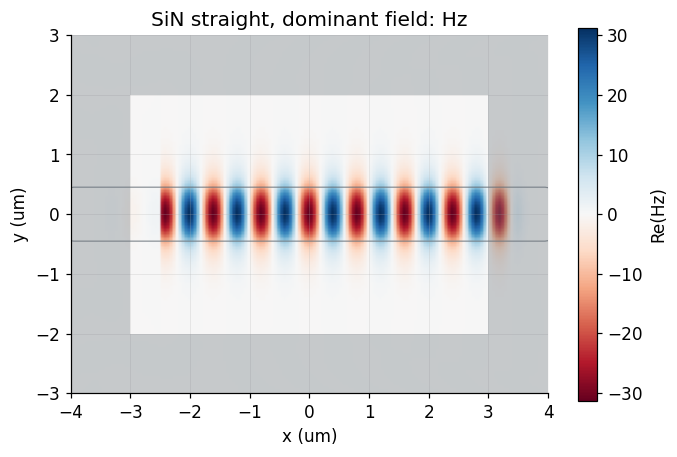

In [9]:
# Plot the dominant field component of the o1-launch run.
fs = result.field_snapshot
fig, ax = plt.subplots(figsize=(7, 4.4))
viz.plot_field(fs.field, fs.eps, fs.extent_um, component=fs.component, ax=ax, pml_um=params["dpml_um"])
ax.set_title(f"SiN straight, dominant field: {fs.component}")
print(f"dominant field component = {fs.component}")
plt.show()

> **STOP -- inspect the electromagnetic field before continuing.**
>
> Check: a clean travelling wave, no standing-wave pattern, and a mode that reaches
> visibly further into the cladding than the Si track's mode does, but still decays well
> before the PML.

### 4.4 S-parameters and SAX export

S11: |S|^2=0.00009  phase=3.138 rad  (at wavelength=1.3500 um)
S12: |S|^2=1.00000  phase=-0.038 rad  (at wavelength=1.3500 um)
S21: |S|^2=1.00000  phase=-0.038 rad  (at wavelength=1.3500 um)
S22: |S|^2=0.00009  phase=3.138 rad  (at wavelength=1.3500 um)


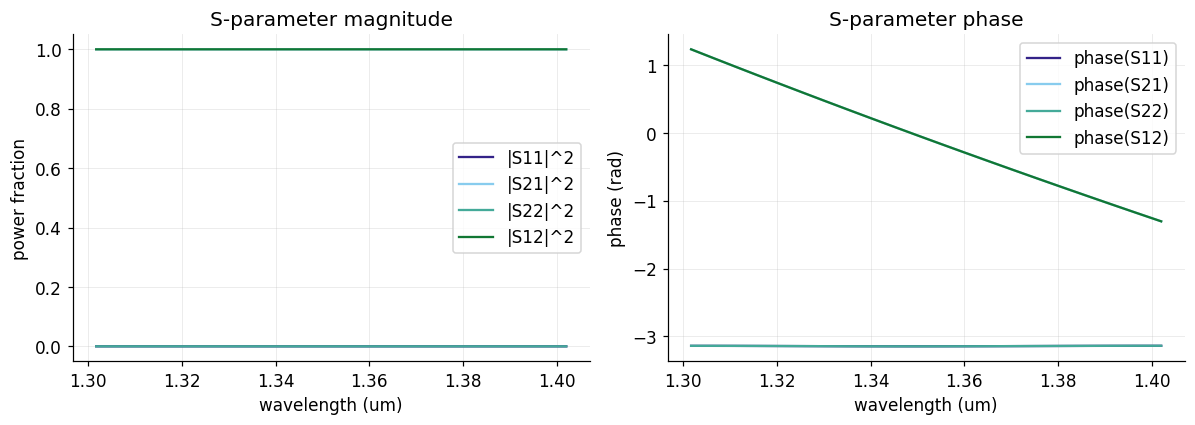

SAX SDict keys: [('o1', 'o1'), ('o1', 'o2'), ('o2', 'o1'), ('o2', 'o2')]


In [10]:
# Complex S-matrix at the band center, the full spectra, and the SAX SDict.
for key in ["11", "12", "21", "22"]:
    s = result.s_matrix[key]
    i_mid = len(s) // 2
    print(f"S{key}: |S|^2={np.abs(s[i_mid])**2:.5f}  phase={np.angle(s[i_mid]):.3f} rad  "
          f"(at wavelength={result.wavelengths_um[i_mid]:.4f} um)")

fig = viz.plot_sparams(result.wavelengths_um, result.s_matrix, pairs=("11", "21", "22", "12"))
plt.show()

sdict = sparams.to_sdict(result.s_matrix, result.port_names)
print("SAX SDict keys:", list(sdict.keys()))

### 4.2b Length sweep (for Section 5's cutback fit)

**The baseline above has been inspected and validated -- only now do we sweep.** As in the
Si track, `length_um` runs from 10.0 to 11.0 µm in 0.1 µm steps. The guided wavelength
$\lambda/n_\mathrm{eff}\approx 0.8$ µm is longer than in Si (0.55 µm), so the sweep
samples each phase cycle more finely.

In [11]:
# One independent FDTD characterization per length; artifacts go to the SiN track's own
# data folder. reuse_existing=True loads a point whose artifact already exists with the
# same geometry, resolution and tolerances instead of re-running it.
LENGTH_SWEEP_UM = [round(float(x), 2) for x in np.arange(10.0, 11.01, 0.1)]
print("sweeping length_um over:", LENGTH_SWEEP_UM)

length_rows = sweep.grid_sweep(
    simulate_fn=waveguide.simulate_baseline,
    base_params=params,
    param_grid={"length_um": LENGTH_SWEEP_UM},
    artifact_dir="../data/sparams/sin_waveguide/sweep",
    component_name="sin_waveguide",
    reuse_existing=True,
)
n_passed = sum(row["validation_passed"] for row in length_rows)
print(f"length sweep: {n_passed}/{len(length_rows)} points passed validation")
sweep.save_manifest(length_rows, "../data/sparams/sin_waveguide/sweep/manifest.csv")

sweeping length_um over: [10.0, 10.1, 10.2, 10.3, 10.4, 10.5, 10.6, 10.7, 10.8, 10.9, 11.0]
[1/11  9%] running sin_waveguide (length_um=10.0) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[2/11  18%] running sin_waveguide (length_um=10.1) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[3/11  27%] running sin_waveguide (length_um=10.2) ...


...

[10/11  90%] running sin_waveguide (length_um=10.9) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


[11/11  100%] running sin_waveguide (length_um=11.0) ...


    reusing the existing artifact (same geometry, resolution and tolerances)


length sweep: 11/11 points passed validation


Fitting at wavelength = 1.3500 um


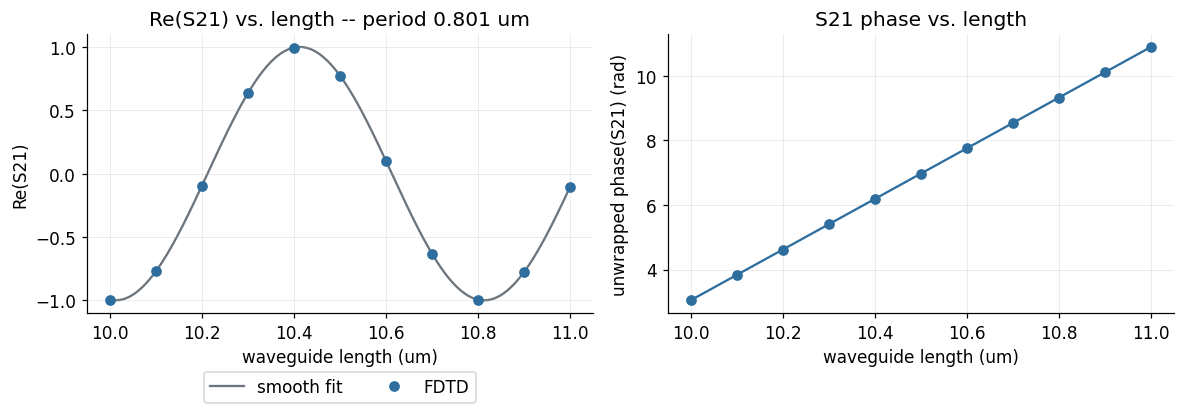

In [12]:
# S21 of every swept length at the band-center wavelength: Re(S21) traces a cosine in L
# and the unwrapped phase a straight line, whose slope Section 5 inverts for n_eff.
i_mid = len(result.wavelengths_um) // 2
wl0 = float(result.wavelengths_um[i_mid])
print(f"Fitting at wavelength = {wl0:.4f} um")

s21_by_length = np.array([
    sparams.load_artifact(f"../data/sparams/sin_waveguide/sweep/sin_waveguide_length{L}").s_matrix["21"][i_mid]
    for L in LENGTH_SWEEP_UM
])
lengths_um = np.array(LENGTH_SWEEP_UM)
phase_unwrapped = np.unwrap(np.angle(s21_by_length))

local_phase_fit = np.polyfit(lengths_um, phase_unwrapped, 1)
L_fine = np.linspace(lengths_um.min(), lengths_um.max(), 400)
re_s21_fine = np.mean(np.abs(s21_by_length)) * np.cos(np.polyval(local_phase_fit, L_fine))
period_um = 2 * np.pi / local_phase_fit[0]

fig, (ax_re, ax_ph) = plt.subplots(1, 2, figsize=(11, 4))
ax_re.plot(L_fine, re_s21_fine, "-", color=style.COLOR_REFERENCE, label="smooth fit", zorder=1)
ax_re.plot(lengths_um, s21_by_length.real, "o", color=style.COLOR_STEEL, label="FDTD", zorder=2)
ax_re.set_xlabel("waveguide length (um)"); ax_re.set_ylabel("Re(S21)")
ax_re.set_title(f"Re(S21) vs. length -- period {period_um:.3f} um")
ax_re.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
ax_ph.plot(lengths_um, phase_unwrapped, "o-", color=style.COLOR_STEEL)
ax_ph.set_xlabel("waveguide length (um)"); ax_ph.set_ylabel("unwrapped phase(S21) (rad)")
ax_ph.set_title("S21 phase vs. length")
fig.tight_layout()
plt.show()

## 5. SAX model fitting -- the cutback method

The unwrapped phase of $S_{21}$ grows as $2\pi n_\mathrm{eff} L/\lambda$, so the slope of
a linear fit against $L$ gives $n_\mathrm{eff}$. As in the Si track the model is lossless:
a straight waveguide in this 2D model has no loss channel, so only the phase is fitted.

In [13]:
# Linear phase fit -> n_eff, and the residual that the STOP checkpoint below reads.
phase_fit = np.polyfit(lengths_um, phase_unwrapped, 1)
n_eff_fit = phase_fit[0] * wl0 / (2 * np.pi)
phase_residual = phase_unwrapped - np.polyval(phase_fit, lengths_um)
print(f"Fitted n_eff         : {n_eff_fit:.4f}")
print(f"max |phase residual| : {np.max(np.abs(phase_residual)):.2e} rad")

Fitted n_eff         : 1.6855
max |phase residual| : 5.85e-07 rad


### 5.2 Group index via MPB dispersion

The same MPB eigenmode solve the Si track uses (`meep_sim.mzi.compute_arm_dispersion`,
which depends only on the cross-section, resolution and PML), cross-checked against a
finite-difference $n_g = n_\mathrm{eff} - \lambda\, dn_\mathrm{eff}/d\lambda$. A converged
1D solve (`slab_modes`) gives a third, grid-independent reference.

In [14]:
# MPB n_eff(wl) and group velocity over the band, plus the converged 1D solver as a
# grid-independent reference for both n_eff and n_g.
from pic_toolkit.meep_sim import mzi as mzi_sim

wl_samples = np.linspace(params["wl_min_um"], params["wl_max_um"], 7)
dispersion = mzi_sim.compute_arm_dispersion(params, wl_samples)
wl0_idx = int(np.argmin(np.abs(wl_samples - wl0)))
n_eff_mpb = float(dispersion["n_eff"][wl0_idx])
n_g_direct = float(dispersion["n_g_direct"][wl0_idx])
dn_dwl = np.gradient(dispersion["n_eff"], wl_samples)
n_g_finite_diff = float(dispersion["n_eff"][wl0_idx] - wl_samples[wl0_idx] * dn_dwl[wl0_idx])

sm_kw = dict(width=params["wg_width_um"], n_core=params["core_index"], n_clad=params["clad_index"], span=8.0)
n_eff_exact = slab_modes.n_eff_single(wl0, **sm_kw)
n_g_exact = slab_modes.group_index(wl0, **sm_kw)

print(f"n_eff: cutback {n_eff_fit:.4f} | MPB {n_eff_mpb:.4f} | 1D solver (converged) {n_eff_exact:.4f}")
print(f"n_g  : MPB {n_g_direct:.4f} | finite-diff {n_g_finite_diff:.4f} | 1D solver {n_g_exact:.4f}")
n_g_fit = n_g_direct

n_eff: cutback 1.6855 | MPB 1.6751 | 1D solver (converged) 1.6753
n_g  : MPB 1.8025 | finite-diff 1.8025 | 1D solver 1.8028


The three $n_\mathrm{eff}$ values bracket the converged one in the same way as in the Si
track: MPB sits slightly low (discretization of the core), and the FDTD cutback slightly
high (Yee-grid numerical dispersion, roughly $(k\Delta x)^2/24$ in phase velocity). The
grid error is smaller here than in Si, because the guided wavelength in SiN is longer.
The design point stores the cutback value, the phase the FDTD runs actually see.

> **STOP -- inspect the fit residual before saving.**
>
> The phase residual should be at the 1e-5 rad level or below, with no structure
> against length.

## 6. Sanity checks

The shared validator (energy conservation, reciprocity, passivity) on the baseline run,
at the default tight tolerances.

In [15]:
validation = checks.run_all_checks(result.s_matrix)
print(json.dumps(validation, indent=2))
assert validation["passed"], "Baseline failed sanity checks -- do not save or use this result."
print("\nBaseline validated.")

{
  "energy_conservation": {
    "max_deviation_port1": 0.00010792494605471603,
    "max_deviation_port2": 0.00010920683745196946,
    "max_deviation": 0.00010920683745196946,
    "max_loss_fraction_allowed": 0.0,
    "tolerance": 0.01,
    "passed": true
  },
  "reciprocity": {
    "max_diff_s12_s21": 5.886008395304495e-06,
    "max_diff_s11_s22": 6.213730147493896e-06,
    "max_diff": 6.213730147493896e-06,
    "tolerance": 0.01,
    "passed": true
  },
  "passivity": {
    "max_magnitude": 1.0000032197442683,
    "tolerance": 0.01,
    "passed": true
  },
  "passed": true
}

Baseline validated.


## 7. Save artifact and design point

Everything goes to `sin/data/`. The Si track's `si/data/design_points/` is never written, so
the Si SAX models cannot pick up SiN numbers by accident.

In [16]:
# Raw S-parameters + metadata as the usual .npz/.json artifact pair.
artifact_stem = "../data/sparams/sin_waveguide/baseline/sin_waveguide_baseline"
metadata = {
    "component": "sin_waveguide",
    "geometry_params": {
        "wg_width_um": result.sim_params["wg_width_um"],
        "length_um": result.sim_params["length_um"],
        "sin_thickness_um": result.sim_params["sin_thickness_um"],
    },
    "material_params": {
        "core_index": result.sim_params["core_index"],
        "clad_index": result.sim_params["clad_index"],
        "core_index_basis": "n_eff-matched EIM: 2D lateral TE0 n_eff = MPB n_eff of the 900x400 nm SiN (n=2.0) strip in SiO2 at 1.35 um",
    },
    "polarization": f"TE ({result.field_snapshot.component} out-of-plane, confirmed dominant -- see Section 4.3)",
    "geometry_source": "gdsfactory (build_gf_component -> build_geometry_from_gds)",
    "meep_resolution": result.sim_params["resolution"],
    "simulation_params": {
        k: result.sim_params[k]
        for k in ["wl_min_um", "wl_max_um", "n_freq", "dpml_um", "cell_x_um",
                  "cell_y_um", "port_offset_um", "source_offset_um"]
    },
    "meep_version": result.sim_params["meep_version"],
    "python_version": result.sim_params["python_version"],
    "creation_date": result.sim_params["creation_date"],
    "validation": validation,
}
sparams.save_artifact(artifact_stem, result.wavelengths_um, result.freqs,
                      result.s_matrix, result.port_names, metadata)
print(f"Saved artifact: {artifact_stem}.npz / .json")

Saved artifact: ../data/sparams/sin_waveguide/baseline/sin_waveguide_baseline.npz / .json


In [17]:
# The SiN design point, read by models/sin_waveguide.py (same record layout as the Si
# track's waveguide.yaml, so the same model code evaluates it).
design_point_path = "../data/design_points/sin_waveguide.yaml"
design_points.save_design_point(design_point_path, {
    "component": "sin_waveguide",
    "parameters": {**metadata["geometry_params"],
                   "core_index": params["core_index"], "clad_index": params["clad_index"]},
    "source_artifact": "sin/data/sparams/sin_waveguide/baseline/sin_waveguide_baseline",
    "fitted_model": {
        "n_eff": float(n_eff_fit),
        "n_g": float(n_g_fit),
        "n_g_direct": float(n_g_direct),
        "n_g_finite_diff": float(n_g_finite_diff),
        "n_eff_1d_solver": float(n_eff_exact),
        "n_g_1d_solver": float(n_g_exact),
        "lambda_um": float(wl0),
        "fit_method": "length-sweep cutback (phase slope vs L; lossless model)",
        "n_g_fit_method": "MPB eigenmode dispersion solve (Section 5.2), cross-checked "
                          "against finite differences and the 1D slab_modes solver",
        "length_sweep_um": LENGTH_SWEEP_UM,
    },
    "provenance": {
        "method": "baseline_plus_length_sweep_cutback_fit",
        "date": metadata["creation_date"],
        "meep_version": metadata["meep_version"],
    },
    "validation": validation,
    "rationale": (
        f"400 nm SiN strip, 0.9 um wide, in the 2D effective-index model (core {params['core_index']}, n_eff-matched to MPB). "
        "Baseline validated at length_um=4.0; n_eff from a 10.0-11.0 um cutback sweep, "
        "n_g from MPB."
    ),
})
print(f"Saved design point: {design_point_path}")

Saved design point: ../data/design_points/sin_waveguide.yaml


## 8. SiN vs. Si: why the SiN mode needs a larger bend radius

The mode profiles come from the same converged 1D solver for every cross-section, so the
comparison is like for like.

- **Si reference.** The partner is the Si reference from Section 1.1: a 500 × 220 nm strip
  calibrated exactly like the SiN strip.
- **Si track.** It is listed as well, to show how far its simplified core index of 2.7
  sits from a real Si strip.

Three quantities govern bend radiation:

- the **lateral index contrast** $\Delta n = n_\mathrm{eff} - n_\mathrm{clad}$, which sets
  how far outside the bend the phase front can still keep up with the mode;
- the **evanescent decay constant**
  $\gamma = k_0\sqrt{n_\mathrm{eff}^2 - n_\mathrm{clad}^2}$, which sets how much field
  sits in the cladding;
- the **confinement factor** $\Gamma$, the fraction of the mode's power in the core.

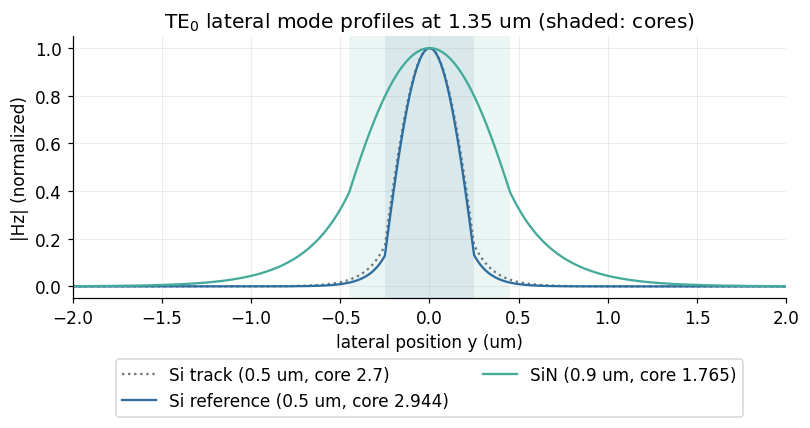

                                           Si track Si reference          SiN
core index (2D)                              2.7000       2.9440       1.7650
width (um)                                     0.50         0.50         0.90
n_eff (1D solver)                            2.4184       2.6713       1.6753
n_g (1D solver, non-dispersive core)         2.9284       3.1845       1.8028
lateral contrast n_eff - n_clad               0.978        1.231        0.235
evanescent decay gamma (1/um)                  9.04        10.47         3.99
decay length 1/gamma (um)                     0.111        0.095        0.251
|Hz| 1/e full width (um)                      0.426        0.412        0.934
core confinement factor                       0.960        0.976        0.909

FDTD cutback n_eff of the SiN strip (Section 5): 1.6855; MPB n_g 1.8025
Si reference / SiN: contrast 5.2x, decay constant 2.6x, gamma*dn 13.7x


In [18]:
# Mode profiles and confinement metrics at the band center, from the converged 1D solver.
# Power density for 2D TE is ~ |Hz|^2 / eps, so the confinement factor integrates
# |Hz|^2/eps over the core and divides by the integral over all y.
cross_sections = {
    "Si track": dict(width=GLOBAL_PARAMS["wg_width_um"], n_core=GLOBAL_PARAMS["core_index"], n_clad=GLOBAL_PARAMS["clad_index"]),
    "Si reference": dict(width=SI_REF_PARAMS["wg_width_um"], n_core=SI_REF_PARAMS["core_index"], n_clad=SI_REF_PARAMS["clad_index"]),
    "SiN": dict(width=params["wg_width_um"], n_core=params["core_index"], n_clad=params["clad_index"]),
}

def mode_metrics(cs, wl=1.35):
    n_eff, y, H, eps = slab_modes.slab_modes(None, wl=wl, span=8.0, dy=0.002, n_modes=1, **cs)
    n_eff, h = float(n_eff[0]), H[:, 0]
    p = np.abs(h) ** 2 / eps
    core = np.abs(y) <= cs["width"] / 2
    gamma = 2 * np.pi / wl * np.sqrt(n_eff ** 2 - cs["n_clad"] ** 2)
    above = y[np.abs(h) >= np.exp(-1) * np.abs(h).max()]
    return dict(y=y, h=h / np.abs(h).max(), n_eff=n_eff, dn=n_eff - cs["n_clad"], gamma=gamma,
                n_g=slab_modes.group_index(wl, span=8.0, **cs),
                gamma_conf=float(p[core].sum() / p.sum()), w_1e=float(above.max() - above.min()))

metrics = {name: mode_metrics(cs) for name, cs in cross_sections.items()}

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, color, ls in [("Si track", style.COLOR_REFERENCE, ":"), ("Si reference", style.COLOR_STEEL, "-"),
                        ("SiN", style.COLOR_TEAL, "-")]:
    cs, m = cross_sections[name], metrics[name]
    ax.plot(m["y"], np.abs(m["h"]), color=color, ls=ls,
            label=f"{name} ({cs['width']:g} um, core {cs['n_core']:g})")
    if name != "Si track":
        ax.axvspan(-cs["width"] / 2, cs["width"] / 2, color=color, alpha=0.10, lw=0)
ax.set_xlim(-2.0, 2.0)
ax.set_xlabel("lateral position y (um)")
ax.set_ylabel("|Hz| (normalized)")
ax.set_title("TE$_0$ lateral mode profiles at 1.35 um (shaded: cores)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.tight_layout()
plt.show()

rows = [
    ("core index (2D)", "n_core", None, "{:.4f}"),
    ("width (um)", "width", None, "{:.2f}"),
    ("n_eff (1D solver)", None, "n_eff", "{:.4f}"),
    ("n_g (1D solver, non-dispersive core)", None, "n_g", "{:.4f}"),
    ("lateral contrast n_eff - n_clad", None, "dn", "{:.3f}"),
    ("evanescent decay gamma (1/um)", None, "gamma", "{:.2f}"),
    ("decay length 1/gamma (um)", None, "decay", "{:.3f}"),
    ("|Hz| 1/e full width (um)", None, "w_1e", "{:.3f}"),
    ("core confinement factor", None, "gamma_conf", "{:.3f}"),
]
for m in metrics.values():
    m["decay"] = 1 / m["gamma"]
print(f"{'':38s} " + " ".join(f"{n:>12s}" for n in metrics))
for label, cs_key, m_key, fmt in rows:
    vals = [cross_sections[n][cs_key] if cs_key else metrics[n][m_key] for n in metrics]
    print(f"{label:38s} " + " ".join(f"{fmt.format(v):>12s}" for v in vals))
print(f"\nFDTD cutback n_eff of the SiN strip (Section 5): {n_eff_fit:.4f}; MPB n_g {n_g_fit:.4f}")
si, sn = metrics["Si reference"], metrics["SiN"]
print(f"Si reference / SiN: contrast {si['dn'] / sn['dn']:.1f}x, decay constant {si['gamma'] / sn['gamma']:.1f}x, "
      f"gamma*dn {si['gamma'] * si['dn'] / (sn['gamma'] * sn['dn']):.1f}x")

**What the comparison shows.** Against a Si strip modelled the same way, the SiN mode
sits on a much smaller index step and decays much more slowly into the cladding:

- **Lateral contrast.** $n_\mathrm{eff}-n_\mathrm{clad}$ is 0.235 for SiN against 1.231
  for the Si reference, 5.2× smaller.
- **Evanescent tail.**
  - The decay length $1/\gamma$ is 0.251 µm against 0.096 µm, 2.6× longer.
  - The mode's 1/e width is 0.93 µm against 0.41 µm.
- **Core confinement.** It differs much less (0.91 against 0.98), because the SiN strip is
  also wider. What changes most is *how fast the field falls off* outside the core, not
  how much of it is inside.
- **The Si track's simplified mode** (dotted) has almost the same lateral |Hz| profile as
  the Si reference. Its mode index is 0.25 lower, though, which means 21 % less contrast
  to the cladding. That contrast, not the profile, sets the bend radiation (notebook 02
  §9.5), which is why the Si track is not used as the Si partner.

**What this means for bends.**
- In a bend, the field at radius $r$ has to travel at $n_\mathrm{eff}\,r/R$ to keep the
  phase front. Beyond the radiation caustic, where this exceeds $n_\mathrm{clad}$, the
  field radiates.
- The caustic sits at a distance
  $x_r \approx R\,(n_\mathrm{eff}-n_\mathrm{clad})/n_\mathrm{clad}$ outside the guide,
  and the radiated fraction scales roughly as $e^{-2\gamma x_r}$.
- So to keep the same radiation loss, $R\,\gamma\,\Delta n$ has to stay about constant.
  This crude estimate predicts that SiN needs about $(\gamma\Delta n)_\mathrm{Si}/(\gamma\Delta n)_\mathrm{SiN} \approx 14\times$
  the Si radius.
- It ignores the junction loss and the barrier's shape. `02_sin_bent_waveguide.ipynb`
  measures the ratio directly and uses the full WKB integral.

---

## 9. Summary

A 400 nm SiN strip, 0.9 µm wide, in the toolkit's 2D effective-index model:

- **Core index.** The 2D core index **1.7650** is n_eff-matched: it reproduces the MPB
  mode index of the real 900 × 400 nm cross-section, 1.6753.
  - The plain slab method (core 1.7786) gives a mode index 0.0125 too high.
  - A 500 × 220 nm Si reference strip is calibrated the same way: MPB 2.671, core 2.944.
  - The Si track's simplified core of 2.7 gives 2.418, which is not a real Si strip.
- **Simulation.** The waveguide was simulated with the Si track's own module
  (`meep_sim/waveguide.py`). The only geometry change was a wider cell for the longer
  mode tail. All checks pass at the default tight tolerances.
- **Fitted model.**
  - Cutback: $n_\mathrm{eff}$ = 1.6855. That is +0.6 % against the converged 1.6753,
    which is FDTD grid dispersion at 20 px/µm.
  - MPB: $n_g$ = 1.8025.
  - Both are stored in `sin/data/design_points/sin_waveguide.yaml`, which
    `models/sin_waveguide.py` reads.
- **Against the Si reference.** The SiN mode has a 5.2× smaller lateral index contrast
  (0.235 against 1.231) and a 2.6× longer evanescent tail. A crude caustic estimate
  predicts about 14× larger bend radii. Continue to `02_sin_bent_waveguide.ipynb` for the
  measured ratio, and its check against the literature.